In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import layers
print(tf.__version__)
#import mlflow

2.7.0


In [3]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import properscoring as ps
from deepgar_skew import QuantileLossModel, model_deepgar_skew_v2
from chart_tools import loss_figure, train_dist_figure, test_dist_figure, get_cycle
from sample_creation import sample_creation, created_naive_forecast, import_latest_data, import_data, invert_scale, invert_normalize

In [4]:
def rmse(y, f):
    assert y.shape[0] == f.shape[0]
    assert y.shape[0] > 0 and y.shape[0] is not None
    return np.sum(((y-f)**2))/y.shape[0]

def sum_neg_like(prob):
    return np.sum(np.log(prob))

In [5]:
def return_density(cond_quant):
    initial_estimates = np.array([1., 1., 1., 3.])

    parameters_est = optimize.leastsq(opt, initial_estimates, (cond_quant, ))

    #print(parameters_est)

    dist_result = SST( 
                  mu = parameters_est[0][0], 
                  sigma = parameters_est[0][1], 
                  nu = parameters_est[0][2],
                  tau = parameters_est[0][3]
                  )

    return dist_result, parameters_est

def opt(parameters, data):
    quantiles_config = [
             0.05,
             0.25,
             0.75,
             0.95]
    dist = SST(mu = parameters[0], sigma = parameters[1], nu = parameters[2], tau = parameters[3])
    error = dist.q(quantiles_config) - data
    return error

In [18]:
class WeightsUpdater(tf.keras.callbacks.Callback):
    def __init__(self, alpha, beta, epochs):
        self.alpha = alpha
        self.beta = beta
        self.total_epochs = epochs
        self.coef = self.alpha/self.total_epochs
    # customize your behavior
    def on_epoch_end(self, epoch, logs={}):
        if epoch > (int(self.total_epochs*0.9)):
            self.alpha = 0.05
            self.beta = 0.95
            
        print (f"\nLoss_weights used:", K.get_value(self.alpha), K.get_value(self.beta))
        
def ls_quantile_cdf(mu, sigma, skewness, tailweight, quantile_values, quantiles):
    loss = 0
    dist = tfp.distributions.SinhArcsinh(loc=mu, scale=sigma, skewness=skewness, tailweight=tailweight)
    q_val = tf.squeeze(quantile_values)
    q_est = dist.quantile(quantiles)
    loss = K.mean(tf.math.squared_difference(q_val, q_est), axis=-1)
    return loss

def multi_tilted_loss_v2(quantiles,y,f):
    '''
    Tilted loss function used
    for simultaneous generation of quantiles
    following (citation)
    '''
    #print y
    #print f
    # The term inside k.mean is a one line simplification of the first equation
    loss = 0

    # quantile loss
    for k in range(len(quantiles)):
        q = quantiles[k]
        e = (y-f[:,k])
        loss += K.mean(q*e + K.clip(-e, K.epsilon(), np.inf), axis=-1)

    # crossing loss
    for i in range(len(quantiles)-1):
        q = quantiles[i]
        q1 = f[:,i]
        q2 = f[:,i+1]
        loss += K.mean(K.maximum(0.0, q1 - q2))

    return loss

In [6]:
def denormalize_sigma(x, scaler):
    if scaler is None:
        result = x
    else:
        result = (x*scaler['std'][0])
    return result

In [7]:
def generate_quantiles(num_quantiles):
    '''
    Create equally spaced quantiles
    '''
    return np.linspace(0.01, 0.99 , num_quantiles).tolist()

In [8]:
# Define the model parameters
param = {
    'NUM_FEATURES': 0,
    'NUM_QUANTILES': 2,
    'SPLIT': 0.75,
    'WINDOW_SIZE': 1,
    '1_COMMON_LSTM_NUM': 128,
    '2_COMMON_LSTM_NUM': 128,
    '1_IND_LSTM_NUM': 64,
    '1_IND_DENSE_NUM': 32,
    '1_IND_DENSE_ACTIVATION': 'relu',
    '1_OUT_DENSE_ACTIVATION': None,
    '1_LEARNING_RATE': 0.001,
    '2_SELECTION_METHOD': "weights", # "weights", "softmax_relu"
    '2_LSTM_NUM': 32,
    '2_DENSE_1_NUM': 16,
    '2_DENSE_1_ACTIVATION': None,
    '2_DENSE_2_ACTIVATION': 'tanh',
    '2_LEARNING_RATE': 0.001,
    'PRED_STEP': 1
}

EPOCHS1 = 95
EPOCHS2 = 2000

# Generate quantiles
#param['QUANTILES'] = generate_quantiles(param['NUM_QUANTILES'])
param['QUANTILES'] = [0.05, 0.25, 0.75, 0.95]

# EPOCHS
# Bulgaria   125
# Estonia    95
# Lithuania  150
# Romania    200


In [9]:
patience = int(EPOCHS1*0.10)
patience

9

In [158]:
country = "Romania"

# Import and generate modeling sample
#dataset = import_latest_data()

data_file_dict = {
    'Bulgaria': 'data_Bulgaria_14.07.2022.csv',
    'Estonia': 'data_Estonia_14.07.2022.csv',
    'Lithuania': 'data_Lithuania_19.07.2022.csv',
    'Romania': 'data_Romania_14.04.2022_13.00.19.csv'
}

datafile = data_file_dict[country]
dataset = import_data(datafile)

# exclude risk factors

spec_dict = {
    'Bulgaria': ['GDP', 'SENTIMENT', 'SOFIX', 'US_BOND_YIELD'],
    'Estonia': ['GDP', 'SENTIMENT', 'OMXTGI_CLOSE'],
    'Lithuania': ['GDP', 'SENTIMENT', 'LT_BOND_YIELD'],
    'Romania': ['GDP', 'SENTIMENT', 'US_BOND_YIELD']
}

# subset predictors
dataset = dataset[spec_dict[country]]

data, scaler = sample_creation(dataset, param, prediction_step = param['PRED_STEP'])

naive = created_naive_forecast(data['TEST_DF'], param['WINDOW_SIZE'])
if isinstance(dataset, pd.DataFrame):
    param['NUM_FEATURES'] = data['TRAIN_DF'].shape[1]
else:
    param['NUM_FEATURES'] = 1

data/data_Romania_14.04.2022_13.00.19.csv


In [159]:
len(dataset)*(param['SPLIT'])

64.5

In [160]:
param['NUM_FEATURES']

3

In [161]:
dataset.columns

Index(['GDP', 'SENTIMENT', 'US_BOND_YIELD'], dtype='object')

In [162]:
epochs_dict = {
    'Bulgaria': 125,
    'Estonia': 95,
    'Lithuania': 95,
    'Romania': 125,
}

In [163]:
import keras.backend as K

patience = 50

early_stopper = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience)

tf.keras.backend.clear_session()

tf.random.set_seed(1234)

data_input = keras.Input(
    shape=(None, param['NUM_FEATURES']), name="data_input"
)

lstm_origin = layers.LSTM(param['1_COMMON_LSTM_NUM'], return_sequences=True)(data_input)
#lstm_lat_factors = layers.LSTM(self._2_common_lstm_layer_num, return_sequences=True)(lstm_origin)

out_layers = []
for i in range(len(param['QUANTILES'])):
    q = param['QUANTILES'][i]
    lstm_layer1 = layers.Dense(param['1_IND_LSTM_NUM'], activation = "tanh")(lstm_origin)
    dense_layer = layers.Dense(param['1_IND_DENSE_NUM'], activation=param['1_IND_DENSE_ACTIVATION'])(lstm_layer1)
    out_layer = layers.Dense(1, activation = param['1_OUT_DENSE_ACTIVATION'], name="q{}".format(int(q*100)))(dense_layer)
    out_layers.append(out_layer)

quantiles_layer = tf.concat(out_layers, 1)

lstm_layer2 = layers.LSTM(param['1_IND_LSTM_NUM'])(lstm_origin)

mu = layers.Dense(1, activation="linear", name='mu')(lstm_layer2)
sigma = layers.Dense(1, activation=lambda x: tf.nn.elu(x)+1, name='sigma')(lstm_layer2)
skewness = layers.Dense(1, activation="linear", name='skewness')(lstm_layer2)
tailweight = layers.Dense(1, activation=lambda x: tf.nn.elu(x)+1, name='tailweight')(lstm_layer2)

y_real = keras.Input(shape=(1, ))
lossF = ls_quantile_cdf(mu,sigma,skewness,tailweight,quantiles_layer,param['QUANTILES'])
lossQ= multi_tilted_loss_v2(param['QUANTILES'],y_real,quantiles_layer)

model1 = keras.Model(
    inputs=[data_input, y_real],
    outputs=[mu, sigma, skewness, tailweight]
)

final_loss = [lossQ, lossF]

model1.add_loss(final_loss)

alpha = K.variable(0.95)
beta = K.variable(0.05)

model1.compile(
optimizer=keras.optimizers.Adam(param['1_LEARNING_RATE']),
loss_weights=[alpha, beta]
)

# Estimate the models
#y_train_dist, y_test_dist, history1, model1 = model_deepgar_skew_v2(param, data, epochs_dict[country], 50)

history1 = model1.fit(
        [data['X_TRAIN'], data['Y_TRAIN']],
        validation_data=[[data['X_TEST'], data['Y_TEST']]],
        epochs=epochs_dict[country],
        batch_size=data['BATCH_SIZE'],
        verbose=1,
        callbacks=[WeightsUpdater(alpha, beta, epochs_dict[country]), early_stopper]
        )

y_train_dist = model1.predict([data['X_TRAIN'],data['Y_TRAIN']])
y_test_dist = model1.predict([data['X_TEST'],data['Y_TEST']])

Epoch 1/125
1/2 [==============>...............] - ETA: 1s - loss: 2.9843
Loss_weights used: 0.95 0.05
2/2 [==============================] - 2s 337ms/step - loss: 2.9719 - val_loss: 3.2007
Epoch 2/125
1/2 [==============>...............] - ETA: 0s - loss: 2.7934
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.7936 - val_loss: 3.0343
Epoch 3/125
1/2 [==============>...............] - ETA: 0s - loss: 2.6706
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.6749 - val_loss: 2.8877
Epoch 4/125
1/2 [==============>...............] - ETA: 0s - loss: 2.5115
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.5652 - val_loss: 2.7525
Epoch 5/125
1/2 [==============>...............] - ETA: 0s - loss: 2.4629
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 12ms/step - loss: 2.4613 - val_loss: 2.6252
Epoch 6/125
1/2 [==============>...............] - ETA

1/2 [==============>...............] - ETA: 0s - loss: 0.7031
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6986 - val_loss: 1.0555
Epoch 45/125
1/2 [==============>...............] - ETA: 0s - loss: 0.7034
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6970 - val_loss: 1.0495
Epoch 46/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6404
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6948 - val_loss: 1.0439
Epoch 47/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6966
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6926 - val_loss: 1.0403
Epoch 48/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6960
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 9ms/step - loss: 0.6906 - val_loss: 1.0378
Epoch 49/125
1/2 [==============>...............] - ETA: 0s - lo

1/2 [==============>...............] - ETA: 0s - loss: 0.6491
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 0.6444 - val_loss: 1.0291
Epoch 88/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6472
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6433 - val_loss: 1.0283
Epoch 89/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6495
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6432 - val_loss: 1.0306
Epoch 90/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6453
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 9ms/step - loss: 0.6421 - val_loss: 1.0304
Epoch 91/125
1/2 [==============>...............] - ETA: 0s - loss: 0.6453
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.6416 - val_loss: 1.0288
Epoch 92/125
1/2 [==============>...............] - ETA: 0s - lo

(<Figure size 720x432 with 1 Axes>,
 <AxesSubplot:title={'center':'Training and Validation Loss - Simultaneous Quantiles Generation & Crossing Loss'}, xlabel='Epochs', ylabel='Loss'>)

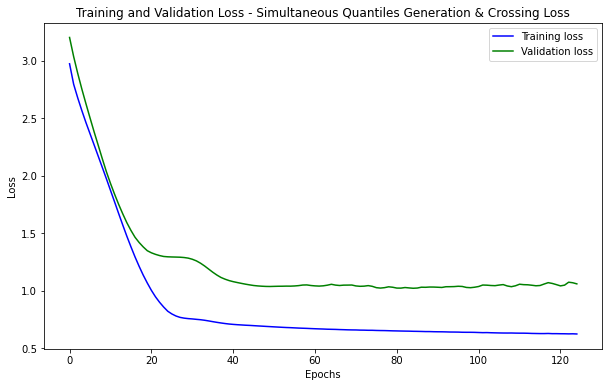

In [164]:
loss_figure(history1)

In [165]:
from keras.utils.vis_utils import plot_model

keras.utils.plot_model(model1, "charts/1step_quantile_model.png", show_shapes=True)

('You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) ', 'for plot_model/model_to_dot to work.')


In [166]:
yhat = model1([data['X_TEST'], data['Y_TEST']])
#yhat

In [167]:
m = yhat[0]#*scaler['std'][0] + scaler['mean'][0]
s = yhat[1]
a = yhat[2]
t = yhat[3]
#pd.DataFrame(np.array(tf.squeeze(m)))
#np.squeeze(np.array(m), axis=2).shape

In [168]:
inference_model = tf.keras.Model(inputs=data_input, outputs=mu)

In [169]:
import lime
from lime import lime_tabular

feature_names=data['TEST_DF'].columns.values.tolist()
feature_names

explainer = lime_tabular.RecurrentTabularExplainer(data['X_TRAIN'], 
                                                   training_labels=data['Y_TRAIN'], 
                                                   feature_names=feature_names,
                                                   discretize_continuous=True,
                                                   mode='regression',
                                                   discretizer='decile')


In [170]:
imp_dict = {
    'obs': [],
    'label': [],
    'imp': []
}

for s in range(len(data['X_TEST'])):
    exp = explainer.explain_instance(data['X_TEST'][s], inference_model.predict)
    exp_map = exp.as_map()
    
    imp_dict['obs'].extend([s] * len(feature_names))
    imp_dict['label'].extend(feature_names[x[0]] for x in exp_map[0])
    imp_dict['imp'].extend([abs(x[1]) for x in exp_map[0]])
    
imp = pd.DataFrame.from_dict(imp_dict)

In [171]:
imp.groupby(['label'])['imp'].mean()/imp.groupby(['label'])['imp'].mean().sum()

label
GDP              0.361805
SENTIMENT        0.270335
US_BOND_YIELD    0.367860
Name: imp, dtype: float64

In [172]:
data['Y_TEST']

array([[ 0.78760308],
       [ 0.9093524 ],
       [ 0.1918609 ],
       [ 0.93351908],
       [ 0.09293008],
       [-0.2296181 ],
       [ 0.39166765],
       [ 0.08771984],
       [-0.14266436],
       [ 0.3696931 ],
       [-0.0774604 ],
       [-0.14972795],
       [-0.16573698],
       [-0.43564829],
       [-7.3414617 ],
       [ 2.52610641],
       [ 1.95068671],
       [ 0.67420022],
       [ 0.44267254],
       [-0.33664087],
       [-0.63965225]])

In [173]:
imp_dict = {
    'label': [],
    'imp': []
}

exp = explainer.explain_instance(data['X_TEST'][-7], inference_model.predict)
exp_map = exp.as_map()
imp_dict['label'].extend(feature_names[x[0]] for x in exp_map[0])
imp_dict['imp'].extend([abs(x[1]) for x in exp_map[0]])

imp = pd.DataFrame.from_dict(imp_dict)
imp.groupby(['label'])['imp'].mean()/imp.groupby(['label'])['imp'].mean().sum()

label
GDP              0.104417
SENTIMENT        0.662251
US_BOND_YIELD    0.233333
Name: imp, dtype: float64

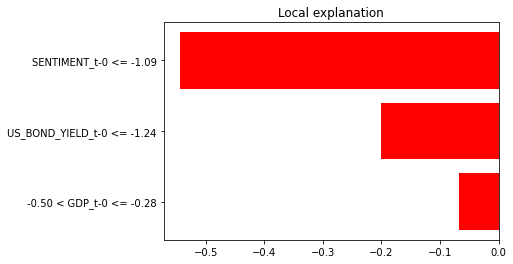

In [174]:
exp = explainer.explain_instance(data['X_TEST'][-7], inference_model.predict)
exp.as_pyplot_figure();

In [154]:
pd_list = [pd.DataFrame(np.array(tf.squeeze(m)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.array(tf.squeeze(s)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.array(tf.squeeze(a)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.array(tf.squeeze(t)), index = data['TEST_DF'].index.to_list()[1:])]

final_df = (pd.concat(pd_list, axis=1))
final_df.set_axis(['LOC', 'STDEV', 'SKEWNESS', 'TAILWEIGHT'], axis=1, inplace=True)
final_df

,LOC,STDEV,SKEWNESS,TAILWEIGHT
2017Q3,0.151064,0.404637,0.100855,1.541978
2017Q4,0.139657,0.523347,-0.026987,1.412133
2018Q1,0.183352,0.517166,-0.070685,1.462927
2018Q2,0.108495,0.425870,0.075521,1.495890
2018Q3,0.180799,0.490890,0.016440,1.454070
2018Q4,0.105171,0.523793,-0.035387,1.400413
2019Q1,0.146664,0.537458,-0.032697,1.393154
2019Q2,0.120730,0.469037,0.030244,1.436498
2019Q3,-0.024814,0.379660,0.052662,1.485921
2019Q4,0.037161,0.513434,-0.046487,1.393078


In [155]:
def denormalize(x, scaler):
    return (x*scaler['std'][0] + scaler['mean'][0])*100

In [156]:
#from skewnormal_v2 import SkewNormal
#dist = SkewNormal(loc=list(np.squeeze(m)), scale=list(np.squeeze(s)), skewness=list(np.squeeze(a))
dist = tfp.distributions.SinhArcsinh(loc=list(np.squeeze(m)), 
                                     scale=list(np.squeeze(s)), 
                                     skewness=list(np.squeeze(a)), 
                                     tailweight=list(np.squeeze(t)))

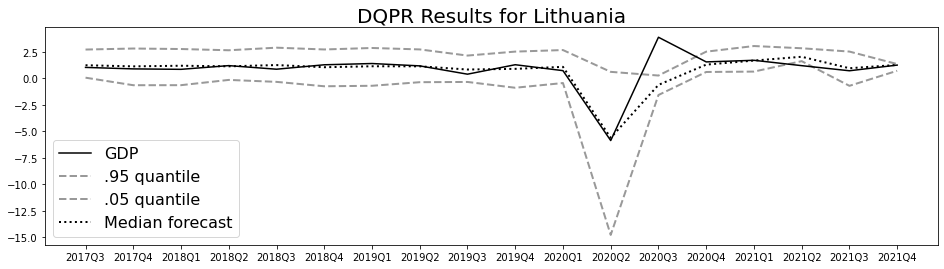

In [157]:
real_y = denormalize(data['Y_TEST'], scaler)
m = denormalize(m, scaler)
upper = denormalize(np.array(dist.quantile(0.95)), scaler)
lower = denormalize(np.array(dist.quantile(0.05)), scaler)
median = denormalize(np.array(dist.quantile(0.5)), scaler)

plt.figure(figsize=[16, 4])  # inches
#plt.style.use('grayscale')
plt.plot(real_y.squeeze(), label='GDP', color='black');
#plt.plot(m, 'r', linewidth=4, label='mean');
plt.plot(upper, linewidth=2, label=r'.95 quantile', linestyle="--", color='black', alpha=0.4);
plt.plot(lower, linewidth=2, label=r'.05 quantile', linestyle="--", color='black', alpha=0.4);
plt.plot(median, linewidth=2, label=r'Median forecast', linestyle="dotted", color='black');
#plt.plot((naive*scaler['std'][0] + scaler['mean'][0])*100, label="Naive Prediction", color='c');

ax=plt.gca();
ax.set_xticks(range(len(data['TEST_DF'])-1))
ax.set_xticklabels(data['TEST_DF'].index.to_list()[1:])
#ax.xaxis.set_ticks_position('bottom')
#ax.yaxis.set_ticks_position('left')
#ax.spines['left'].set_position(('data', 0))
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['left'].set_smart_bounds(True)
#ax.spines['bottom'].set_smart_bounds(True)
plt.legend(fontsize=16)
plt.title("DQPR Results for "+country, fontsize=20)
plt.savefig('../results/charts_19042023/dqpr_'+country.lower()+'.png')


In [72]:
scores = {'Country': [],
          'Model':[],
          'RMSE': [],
          'MAE': [],
          'CRPS': []}

In [73]:
yhat = model1([data['X_TEST'], data['Y_TEST']])
m = yhat[0]#*scaler['std'][0] + scaler['mean'][0]
s = yhat[1]
a = yhat[2]
t = yhat[3]

dist = tfp.distributions.SinhArcsinh(loc=list(denormalize(np.squeeze(m), scaler)), 
                                     scale=list(denormalize_sigma(np.squeeze(s), scaler)), 
                                     skewness=list(np.squeeze(a)), 
                                     tailweight=list(np.squeeze(t)))

samples = dist.sample(200)
descaled_mean = denormalize(m, scaler)

scores['Country'].append(country)
scores['Model'].append('DQPR')
scores['CRPS'].append(ps.crps_ensemble(real_y.squeeze(), np.array(samples).squeeze().T).mean())
scores['RMSE'].append(mean_squared_error(real_y.squeeze(), descaled_mean, squared=False))
scores['MAE'].append(mean_absolute_error(real_y.squeeze(), median.squeeze()))

In [74]:
scores

{'Country': ['Bulgaria'],
 'Model': ['DQPR'],
 'RMSE': [1.7030066545871687],
 'MAE': [0.8781652081099297],
 'CRPS': [1.0693090547904558]}

In [77]:
data['X_TEST'][-7]

array([[-0.86383339, -8.66797889, -0.95910114, -0.94282769]])

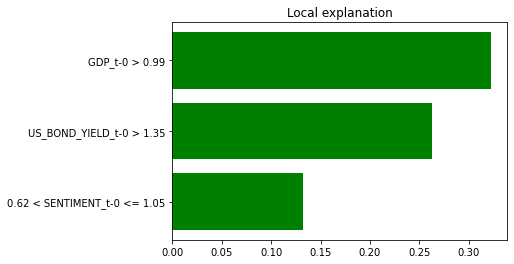

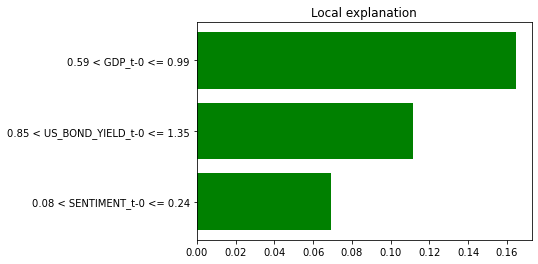

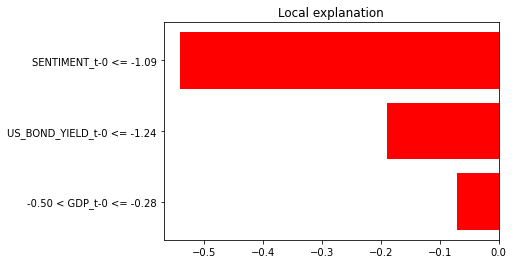

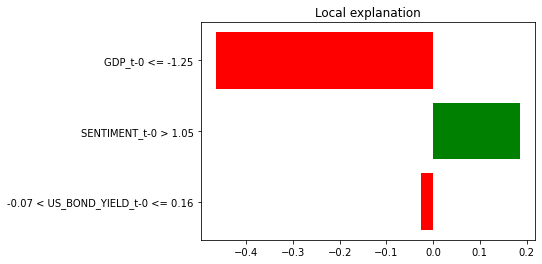

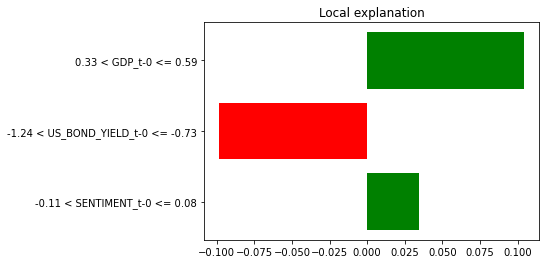

In [55]:
import warnings
from lime import submodular_pick
sp_obj = submodular_pick.SubmodularPick(explainer, data['X_TEST'], inference_model.predict, sample_size=len(data['X_TEST']), num_features=param['NUM_FEATURES'], num_exps_desired=5)
[exp.as_pyplot_figure() for exp in sp_obj.sp_explanations];

(array([5.71428563, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 4.28571326]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ],
       dtype=float32),
 <BarContainer object of 10 artists>)

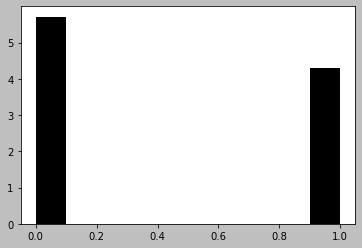

In [395]:
pit = pd.DataFrame(np.array(dist.cdf(real_y.squeeze())), index = data['TEST_DF'].index.to_list()[param['WINDOW_SIZE']:])

plt.hist(pit, 10, density=True)

In [144]:
real_y.min()

-7.3236513

In [145]:
median.min()

-7.453262

In [30]:
data['Y_TEST']

array([[ 8.27549239e-02],
       [ 1.73591854e-02],
       [-2.44187258e-03],
       [ 1.62318617e-01],
       [ 3.00023550e-03],
       [ 1.99208004e-01],
       [ 2.55201535e-01],
       [ 1.50900641e-01],
       [-2.17644250e-01],
       [ 2.02012256e-01],
       [-6.04784053e-02],
       [-3.16249779e+00],
       [ 1.42107094e+00],
       [ 3.26822268e-01],
       [ 3.98520979e-01],
       [ 1.60896150e-01],
       [-6.57521406e-02],
       [ 1.85165811e-01]])

In [31]:
dist_prob = pd.DataFrame(np.array(dist.prob(np.squeeze(data['Y_TEST']))), index = data['TEST_DF'].index.to_list()[1:])

dist_prob

,0
2017Q3,1.360231
2017Q4,0.930860
2018Q1,0.861318
2018Q2,1.292431
2018Q3,0.895899
2018Q4,0.955779
2019Q1,0.914920
2019Q2,1.149834
2019Q3,0.964374
2019Q4,0.872770


In [32]:
recession = np.full(np.squeeze(real_y).shape, -0.001)
dist_cdf = pd.DataFrame(np.array(dist.cdf(list(recession))), index = data['TEST_DF'].index.to_list()[1:])
dist_cdf

,0
2017Q3,0.259853
2017Q4,0.373050
2018Q1,0.344690
2018Q2,0.330087
2018Q3,0.305129
2018Q4,0.409410
2019Q1,0.374269
2019Q2,0.352453
2019Q3,0.514364
2019Q4,0.479620


In [33]:
#country = datafile[datafile.find('/data_')+len('/data_'):datafile.rfind('_')]

In [35]:
pd_list = [pd.DataFrame(real_y.squeeze(), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(median, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.sqrt(np.power((real_y.squeeze()-median),2)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(lower, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(upper, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(upper-lower, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(list(denormalize(np.squeeze(m), scaler)), index = data['TEST_DF'].index.to_list()[1:]), 
           pd.DataFrame(list(np.squeeze(s)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(list(np.squeeze(a)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(list(np.squeeze(t)), index = data['TEST_DF'].index.to_list()[1:]),
           dist_prob,
           dist_cdf]

final_df = (pd.concat(pd_list, axis=1))
final_df.set_axis(['GDP Actual', 
                   'Median',
                   'RMSE',
                   '.05 Quantile',
                   '.95 Quantile',
                   'IQR',
                   'Location', 
                   'Standard Deviation', 
                   'Skewness',
                   'Tailweight',
                   'Predictive Score', 
                   'Probability of recession'], axis=1, inplace=True)

#country = 'BG'

#final_df.to_csv('data/small_countries/'+'results_deepgar_'+country +'.csv')
#print("Exporting file to csv format at "+now.strftime('%d.%m.%Y_%H.%M.%S'))

(array([ 9., 15.,  9.,  9., 13.]),
 array([0.00197414, 0.19186981, 0.38176548, 0.5716612 , 0.7615568 ,
        0.9514525 ], dtype=float32),
 <BarContainer object of 5 artists>)

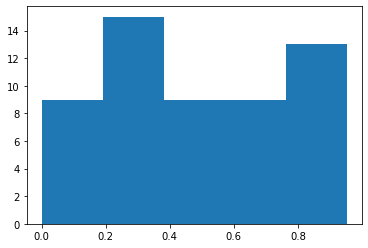

In [36]:
yhat_train = model1([data['X_TRAIN'], data['Y_TRAIN']])

m_train = yhat_train[0]
s_train = yhat_train[1]
a_train = yhat_train[2]
t_train = yhat_train[3]

dist_train = tfp.distributions.SinhArcsinh(loc=list(np.squeeze(m_train)), 
                                     scale=list(np.squeeze(s_train)), 
                                     skewness=list(np.squeeze(a_train)), 
                                     tailweight=list(np.squeeze(t_train)))

pit = pd.DataFrame(np.array(dist_train.cdf(np.squeeze(data['Y_TRAIN']))), index = data['TRAIN_DF'].index.to_list()[1:])

plt.hist(pit, 5)
#pit

In [37]:
denormalize(data['Y_TEST'], scaler)
#real_y

array([[ 1.036133 ],
       [ 0.8970863],
       [ 0.8549846],
       [ 1.2053041],
       [ 0.8665558],
       [ 1.2837396],
       [ 1.402795 ],
       [ 1.1810268],
       [ 0.3974138],
       [ 1.2897021],
       [ 0.7315853],
       [-5.8640365],
       [ 3.8817072],
       [ 1.5550775],
       [ 1.7075258],
       [ 1.2022796],
       [ 0.7203721],
       [ 1.2538826]])

In [38]:
print(rmse(real_y, np.squeeze(median)))

104.21731300479571


In [39]:
print(sum_neg_like(np.array(dist_prob)))

-15.024492


In [40]:
yhat = model1([data['X_TRAIN'], data['Y_TRAIN']])
#yhat

In [41]:
m = yhat[0]
s = yhat[1]
a = yhat[2]
t = yhat[3]
pd.DataFrame(np.array(s))

,0
0,0.527162
1,0.356949
2,0.520349
3,0.428795
4,0.450352
5,0.545496
6,0.534286
7,0.438093
8,0.384087
9,0.423028


In [42]:
dist = tfp.distributions.SinhArcsinh(loc=list(np.squeeze(m)), scale=list(np.squeeze(s)), skewness=list(np.squeeze(a)), tailweight=list(np.squeeze(t)))

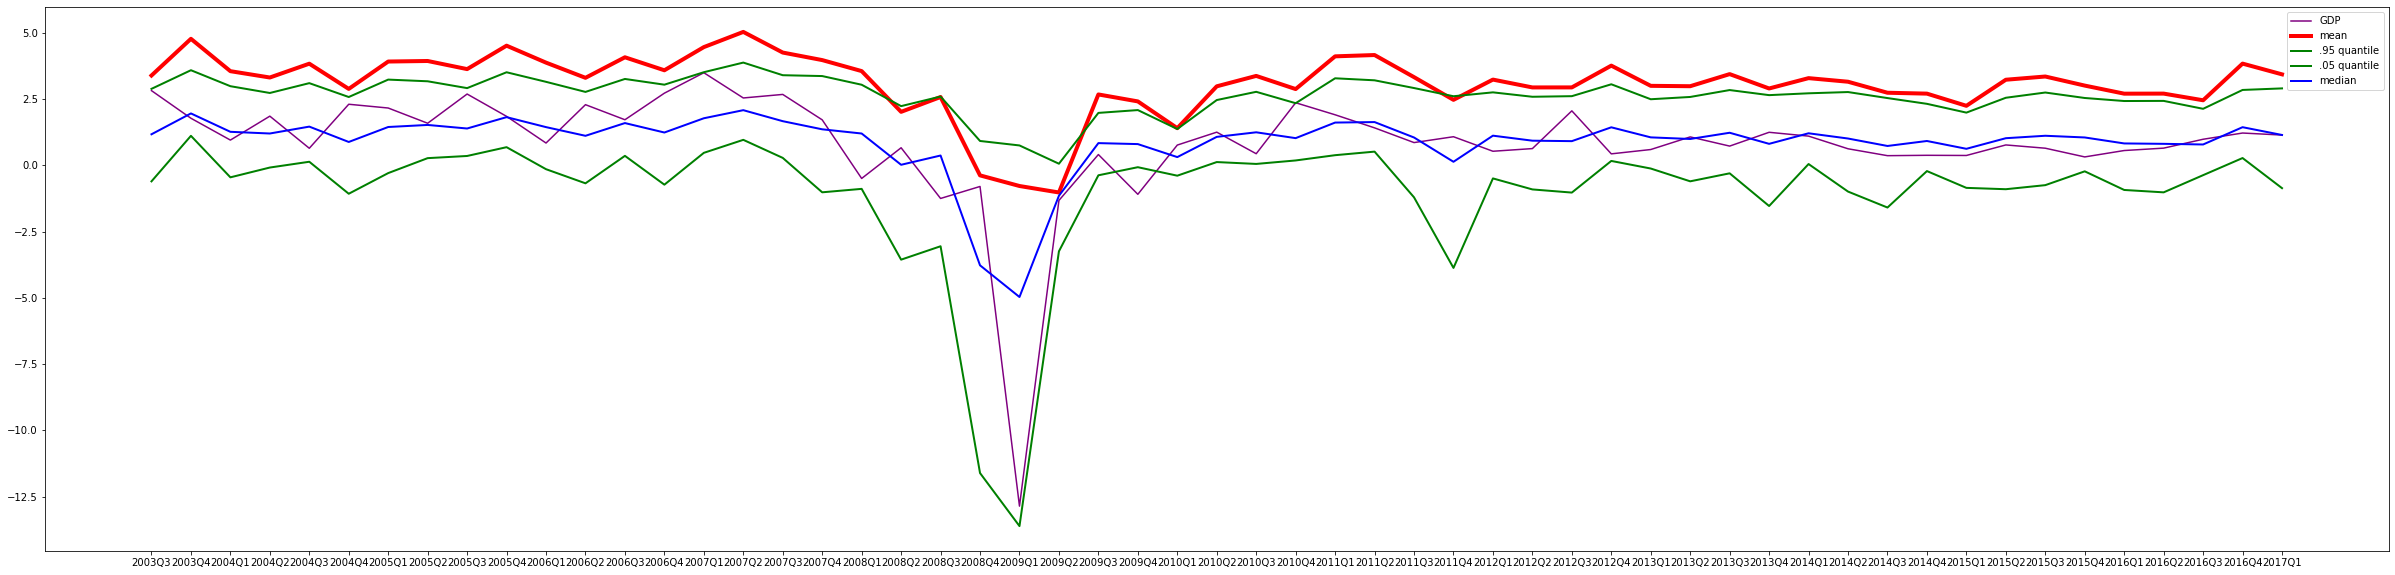

In [44]:
plt.figure(figsize=[42, 10])  # inches
real_y = (data['Y_TRAIN'].squeeze()*scaler['std'][0] + scaler['mean'][0])*100
m = (m*scaler['std'][0] + scaler['mean'][0])*100
plt.plot(real_y, label='GDP', color='purple');
plt.plot(m, 'r', linewidth=4, label='mean');
upper = (np.array(dist.quantile(0.95))*scaler['std'][0] + scaler['mean'][0])*100
lower = (np.array(dist.quantile(0.05))*scaler['std'][0] + scaler['mean'][0])*100
median = (np.array(dist.quantile(0.5))*scaler['std'][0] + scaler['mean'][0])*100

plt.plot(upper, 'g', linewidth=2, label=r'.95 quantile');
plt.plot(lower, 'g', linewidth=2, label=r'.05 quantile');
plt.plot(median, 'b', linewidth=2, label=r'median');


ax=plt.gca();
ax.set_xticks(range(len(data['TRAIN_DF'])-1))
ax.set_xticklabels(data['TRAIN_DF'].index.to_list()[1:])
#ax.xaxis.set_ticks_position('bottom')
#ax.yaxis.set_ticks_position('left')
#ax.spines['left'].set_position(('data', 0))
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['left'].set_smart_bounds(True)
#ax.spines['bottom'].set_smart_bounds(True)
plt.legend()

#plt.savefig('charts/direct_density_estimation_train_set.png')

In [45]:
data['Y_TEST'].shape

(18, 1)

## AR1

In [396]:
country = "Romania"

# Import and generate modeling sample
#dataset = import_latest_data()

data_file_dict = {
    'Bulgaria': 'data_Bulgaria_14.07.2022.csv',
    'Estonia': 'data_Estonia_14.07.2022.csv',
    'Lithuania': 'data_Lithuania_19.07.2022.csv',
    'Romania': 'data_Romania_14.04.2022_13.00.19.csv'
}

datafile = data_file_dict[country]

dataset = import_data(datafile)

# exclude risk factors
#dataset = dataset.drop(['BRENT'], axis=1) # sufficient

# leave only gdp
dataset = dataset[['GDP']]

data, scaler = sample_creation(dataset, param, prediction_step = param['PRED_STEP'])

naive = created_naive_forecast(data['TEST_DF'], param['WINDOW_SIZE'])
if isinstance(dataset, pd.DataFrame):
    param['NUM_FEATURES'] = data['TRAIN_DF'].shape[1]
else:
    param['NUM_FEATURES'] = 1

data/data_Romania_14.04.2022_13.00.19.csv


In [397]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20)

def keras_pred(early_stop):
    # Set input_dim for the number of features.
    if len(data['X_TRAIN'].shape) == 1:
        input_dim = 1
    else:
        input_dim = data['X_TRAIN'].shape[0]
    model = keras.Sequential([
      keras.layers.Dense(1, activation='linear')
    ])
    
    model.compile(loss='mse', optimizer=keras.optimizers.Adam(0.001))
    model.fit(data['X_TRAIN'], data['Y_TRAIN'], epochs=200, batch_size=1,
              verbose=0, validation_split=0.2, callbacks=[early_stop])
    
    # Predict the quantile
    return model.predict(data['X_TEST']), model.predict(data['X_TRAIN']), model

In [398]:
forecast_test, forecast_train, ar_model = keras_pred(early_stop)

In [399]:
descaled_mean = denormalize(forecast_test, scaler)

stdev = np.std(data['X_TRAIN'].squeeze()-forecast_train.squeeze())
stdev

0.6619229588416862

In [400]:
descaled_mean.shape

(21, 1, 1)

In [401]:
#descaled_mean

In [402]:
sigma_array = np.full(descaled_mean.squeeze().shape, stdev, dtype=np.float32)
sigma_array = denormalize_sigma(sigma_array, scaler)
sigma_array.squeeze().shape

(21,)

In [403]:
sigma_array[0]

0.01007066

In [404]:
dist = tfp.distributions.Normal(loc=descaled_mean.squeeze(), 
                                scale=sigma_array)

In [405]:
upper.shape

(21,)

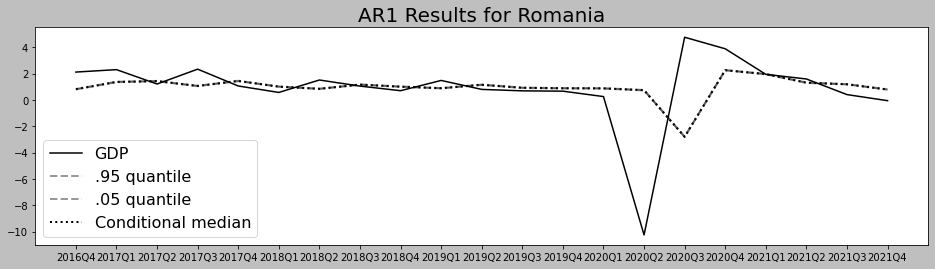

In [406]:
real_y = denormalize(data['Y_TEST'], scaler)
#m = denormalize(m, scaler)
upper = np.array(dist.quantile(0.95))
lower = np.array(dist.quantile(0.05))
median = np.array(dist.quantile(0.5))

plt.figure(figsize=[16, 4])  # inches

plt.plot(real_y.squeeze(), label='GDP', color='black');
#plt.plot(m, 'r', linewidth=4, label='mean');
plt.plot(upper, 'black', alpha=0.4, linewidth=2, label=r'.95 quantile', linestyle="--");
plt.plot(lower, 'black', alpha=0.4, linewidth=2, label=r'.05 quantile', linestyle="--");
plt.plot(median, 'black', linewidth=2, label=r'Conditional median', linestyle="dotted");
#plt.plot((naive*scaler['std'][0] + scaler['mean'][0])*100, label="Naive Prediction", color='c');

ax=plt.gca();
ax.set_xticks(range(len(data['TEST_DF'])-1))
ax.set_xticklabels(data['TEST_DF'].index.to_list()[1:])
#ax.xaxis.set_ticks_position('bottom')
#ax.yaxis.set_ticks_position('left')
#ax.spines['left'].set_position(('data', 0))
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['left'].set_smart_bounds(True)
#ax.spines['bottom'].set_smart_bounds(True)
plt.legend(fontsize=16)
plt.title("AR1 Results for "+country, fontsize=20)
plt.savefig('../results/charts_19042023/ar1_'+country.lower()+'.png')


In [407]:
samples = dist.sample(200)

scores['Country'].append(country)
scores['Model'].append('AR1')
scores['CRPS'].append(ps.crps_ensemble(real_y.squeeze(), np.array(samples).squeeze().T).mean())
scores['RMSE'].append(mean_squared_error(real_y.squeeze(), descaled_mean.squeeze(), squared=False))
scores['MAE'].append(mean_absolute_error(real_y.squeeze(), descaled_mean.squeeze()))

In [408]:
scores

{'Country': ['Romania', 'Romania'],
 'Model': ['DQPR', 'AR1'],
 'RMSE': [2.0735162046452107, 2.9931552211950145],
 'MAE': [1.0263290769257072, 1.417801056089649],
 'CRPS': [1.0648458406279342, 1.412150752230681]}

In [ ]:
pd.DataFrame.from_dict(scores)